Just rewriting what the goals of the assignment are here:
1) Target variable selection, choose one high level water-quality variable to predict at the target (except temp and salinity) & select input variables from the remaining choices
2) Select three different machine learning techniques, and implement the models with the water quality data
3) For each model, display the R2 value and a scatterplot of target values vs. model-predicted values
4) Explain hyperparameter selection/tuning in a markdown cell

In [1]:
# Import packages - pretty much using exactly what we've used in class

%matplotlib inline 
# the line above is a command that configures Matplotlib to render plot images directly inside the Jupyter Notebook, beneath the code cell that generated them.
# we will need to have "scikit-learn" package installed in our local environment, after activating the environment (such as funtimes)
# example (Mac): 
#    conda activate funtimes
#    conda install scikit-learn -y
# more instructions if needed: https://scikit-learn.org/stable/install.html

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random

# Linear model and basic functions from scikit-learn
from sklearn import datasets, linear_model
from sklearn.metrics import mean_squared_error, r2_score # to get statistical info out of models
from sklearn.model_selection import train_test_split # to split up training vs. testing data

# Specific models 
from sklearn.neighbors import KNeighborsRegressor # K nearest neighbors regression
from sklearn.neighbors import RadiusNeighborsRegressor # Radius nearest neighbors regression
from sklearn.ensemble import RandomForestRegressor # Random forest regression

In [2]:
# Load in data & check out what it looks like

infile = r"C:\Users\talia\OneDrive - Old Dominion University\Documents\Old Dominion\Environmental Data Science\OEAS805\HW3\CBP_TWQM_MAIN_WQ_2021_2026_surface.csv"
data = pd.read_csv(infile, sep=',')

print(data)

     Station  FieldActivityId  Cruise Program Project DataCollector  \
0     CB4.1C           785801  BAY900    TWQM    MAIN         MDDNR   
1     CB4.1C           785781  BAY898    TWQM    MAIN         MDDNR   
2     CB4.1C           785724  BAY895    TWQM    MAIN         MDDNR   
3     CB4.1C           785723  BAY894    TWQM    MAIN         MDDNR   
4     CB4.1C           785680  BAY893    TWQM    MAIN         MDDNR   
...      ...              ...     ...     ...     ...           ...   
1218  CB4.1C           699206  BAY814    TWQM    MAIN         MDDNR   
1219  CB4.1C           611589  BAY812    TWQM    MAIN         MDDNR   
1220  CB4.1C           608274  BAY806    TWQM    MAIN         MDDNR   
1221  CB4.1C           608260  BAY805    TWQM    MAIN         MDDNR   
1222  CB4.1C           608240  BAY802    TWQM    MAIN         MDDNR   

     DataProvider  Latitude  Longitude  SampleDate  ... Qualifier  \
0           MDDNR  38.82593  -76.39945  11/18/2025  ...       NaN   
1        

In [3]:
# That's a lot to look at, so look at just the columns
data.columns

Index(['Station', 'FieldActivityId', 'Cruise', 'Program', 'Project',
       'DataCollector', 'DataProvider', 'Latitude', 'Longitude', 'SampleDate',
       'SampleTime', 'TotalDepthM', 'UpperPycnoclineDepthM',
       'LowerPycnoclineDepthM', 'SampleDepthM', 'Layer', 'SampleType',
       'SampleReplicate', 'Parameter', 'Qualifier', 'MeasureValue',
       'MeasureUnit', 'Method', 'Lab', 'Problem', 'PrecisionPC', 'BiasPC',
       'Details', 'TierLevel'],
      dtype='str')

In [4]:
# We're interested in "Parameter"
# Going to want to identify the water quality variables I'm interested in and then probably separate that from the rest of the data for ease of plotting
# Look at the unique options in parameter
variables = data['Parameter'].unique()
print(variables)

<ArrowStringArray>
[    'CHLA',      'DIN',       'DO',      'DON',      'DOP',       'KD',
     'NH4F',    'NO23F',     'NO2F',     'NO3F',       'PC',       'PH',
     'PHEO',       'PN',     'PO4F',       'PP', 'SALINITY',   'SECCHI',
  'SIGMA_T',   'SPCOND',      'TDN',      'TDP',       'TN',      'TON',
       'TP',      'TSS',    'WTEMP']
Length: 27, dtype: str


The way the parameter column was organized in the original dataset is confusing because it's all stacked on each other vertically, so it's hard to tell which parameter measurements correspond to the same sample. This is important to know in order to assess any sort of relationships between parameter variables. 

In [5]:
# I asked Gemini how I could unstack this table and make each paramater it's own column because it felt like a lot of work to do by hand and I couldn't
# think of a simple way that I already knew how to implement

# Define columns that identify a unique sample event
sample_id_cols = [
    "Station",
    "SampleDate",
    "SampleTime",
]

# Pivot so parameters become separate columns
unstacked_data = data.pivot_table(
    index=sample_id_cols,
    columns="Parameter",
    values="MeasureValue",
    aggfunc="mean",  # This handles samples that may have been measured twice with different methods (mostly applies to DIN) 
).reset_index()

# Look at the new data frame
print(unstacked_data)

# Save output
unstacked_data.to_csv("WQ_unstacked_surface.csv", index=False) # Just so I can take a closer look at it in Excel rather than just on here

Parameter Station  SampleDate SampleTime    CHLA       DIN    DO       DON  \
0          CB4.1C   1/10/2023   12:02:00  15.806  0.620000  12.3  0.230000   
1          CB4.1C   1/13/2025   14:51:00   6.255  0.115750  13.1  0.274250   
2          CB4.1C   1/24/2024   12:09:00  20.719  0.646000  13.5  0.274000   
3          CB4.1C  10/23/2024   12:47:00  12.602  0.011650   9.7  0.278350   
4          CB4.1C   10/5/2021   12:47:00   7.595  0.270000   7.3  0.260000   
5          CB4.1C   10/5/2023   12:59:00   6.515  0.157000   7.2  0.263000   
6          CB4.1C   10/6/2022   14:40:00   3.524  0.122200   8.1  0.277800   
7          CB4.1C   10/6/2025   12:29:00   7.049  0.014950   8.8  0.335050   
8          CB4.1C  11/15/2022   12:00:00   3.952  0.098600   8.4  0.271400   
9          CB4.1C  11/16/2023   12:11:00  13.564  0.140000  10.5  0.300000   
10         CB4.1C  11/17/2021   11:57:00  17.444  0.444000  10.4  0.286000   
11         CB4.1C  11/18/2025   15:00:00  11.000  0.046900   9.9

I have decided I want to try to predict DIN using temperature, salinity, and pH. Starting simple is best, so I will start with a simple linear regression for each of these things.

y = -0.01 * x + 0.42
Mean squared error: 0.01
Coefficient of determination (R-squared): 0.62


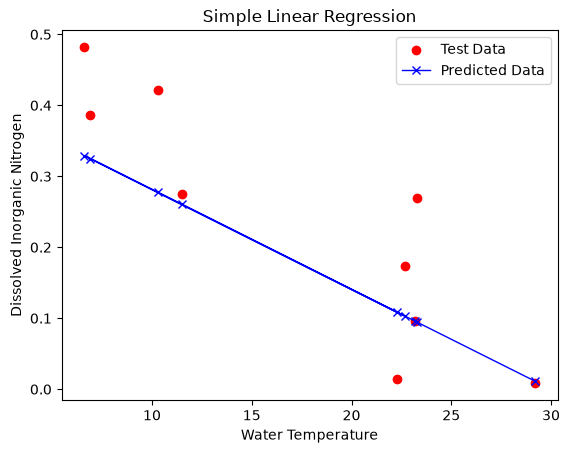

In [6]:
# FOR WATER TEMPERATURE

# Create new variables for x and y so I don't have to index from the data frame every time
temp = unstacked_data[['WTEMP']]
DIN = unstacked_data[['DIN']]

# This all comes from the linear regression examples we did in class
# Split the data into training/testing sets
temp_train,temp_test,DIN_train,DIN_test = train_test_split(temp,DIN,test_size=0.2,random_state=4) # The 0.2 makes the test data 20% of our target
# This separates the data into two sets:
# Training set: Used to train the model.
# Testing set: Reserved to evaluate how well the model generalizes to new data.
# random_state=4: A seed number that ensures the random split is reproducible every time you run the code.

# Create linear regression object
regr = linear_model.LinearRegression()
# The "linear_model.LinearRegression" uses an ordinary least squares, minimizes the sum of squared residuals between predictions and actual values
# If you wanted a different optimization method (like Ridge, Lasso, or ElasticNet), you would instantiate a different class (e.g., linear_model.Ridge())

# Train the model using the training sets
regr.fit(temp_train, DIN_train)

# Make predictions using the testing set
DIN_pred = regr.predict(temp_test)

# Evaluate model performance:
# The coefficients of the line y_pred = m * x_test + b
print(f"y = {regr.coef_[0][0]:.2f} * x + {regr.intercept_[0]:.2f}")
# The mean squared error (lower numbers, better accuracy)
print('Mean squared error: %.2f'
      % mean_squared_error(DIN_test, DIN_pred))
# The coefficient of determination: 1 is perfect prediction
print('Coefficient of determination (R-squared): %.2f'
      % r2_score(DIN_test, DIN_pred))

# Plot outputs
plt.scatter(temp_test, DIN_test,  color='red', label="Test Data")
plt.plot(temp_test, DIN_pred,  '-x', color='blue', linewidth=1, label="Predicted Data")
plt.xlabel('Water Temperature')
plt.ylabel('Dissolved Inorganic Nitrogen')
plt.legend()
plt.title('Simple Linear Regression')
plt.show()

y = -0.02 * x + 0.45
Mean squared error: 0.03
Coefficient of determination (R-squared): 0.06


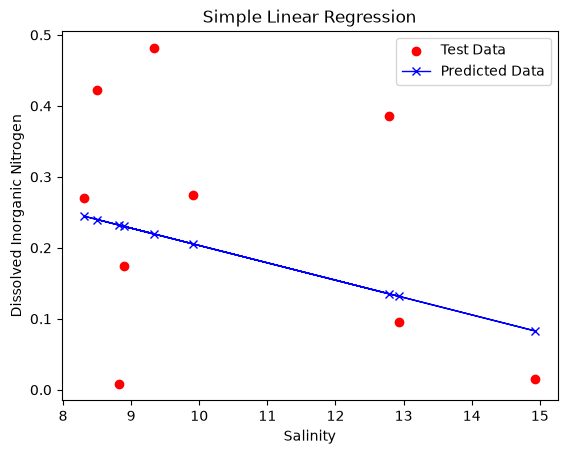

In [8]:
# FOR SALINITY

sal = unstacked_data[['SALINITY']] # This changed

sal_train,sal_test,DIN_train,DIN_test = train_test_split(sal,DIN,test_size=0.2,random_state=4) 

regr = linear_model.LinearRegression()

regr.fit(sal_train, DIN_train)

DIN_pred = regr.predict(sal_test)

print(f"y = {regr.coef_[0][0]:.2f} * x + {regr.intercept_[0]:.2f}") # Why doesn't it like this line?

print('Mean squared error: %.2f'
      % mean_squared_error(DIN_test, DIN_pred))

print('Coefficient of determination (R-squared): %.2f'
      % r2_score(DIN_test, DIN_pred))

plt.scatter(sal_test, DIN_test,  color='red', label="Test Data")
plt.plot(sal_test, DIN_pred,  '-x', color='blue', linewidth=1, label="Predicted Data")
plt.xlabel('Salinity')
plt.ylabel('Dissolved Inorganic Nitrogen')
plt.legend()
plt.title('Simple Linear Regression')
plt.show()

y = 0.12 * x + -0.83
Mean squared error: 0.04
Coefficient of determination (R-squared): -0.40


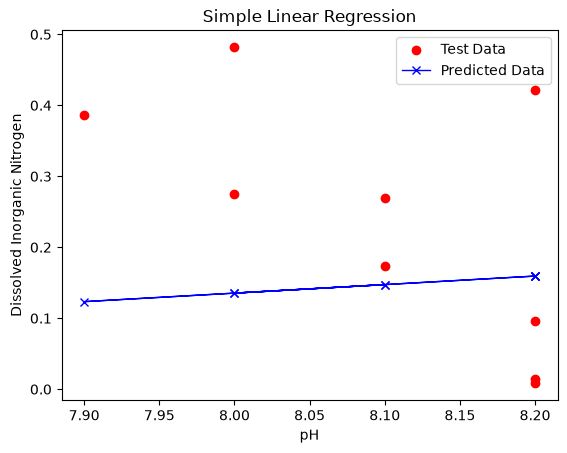

In [9]:
# FOR pH

pH = unstacked_data[['PH']] # This changed

pH_train,pH_test,DIN_train,DIN_test = train_test_split(pH,DIN,test_size=0.2,random_state=4)

regr = linear_model.LinearRegression()

regr.fit(pH_train, DIN_train)

DIN_pred = regr.predict(pH_test)

print(f"y = {regr.coef_[0][0]:.2f} * x + {regr.intercept_[0]:.2f}")

print('Mean squared error: %.2f'
      % mean_squared_error(DIN_test, DIN_pred))

print('Coefficient of determination (R-squared): %.2f'
      % r2_score(DIN_test, DIN_pred))

plt.scatter(pH_test, DIN_test,  color='red', label="Test Data")
plt.plot(pH_test, DIN_pred,  '-x', color='blue', linewidth=1, label="Predicted Data")
plt.xlabel('pH')
plt.ylabel('Dissolved Inorganic Nitrogen')
plt.legend()
plt.title('Simple Linear Regression')
plt.show()

The only one of these that really seemed to work was predicting DIN with water temperature. An R2 of 0.62 is pretty good, and indicates a positive linear correlation. Next I will try a k nearest neighbors (KNN) regression with DIN and water temperature.

Coefficient of determination (R-squared): 0.66


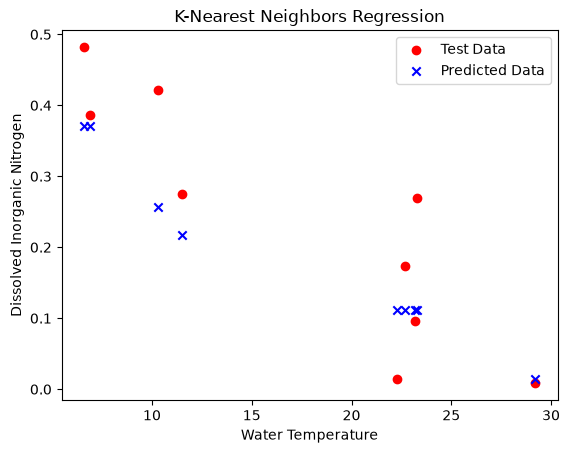

In [20]:
# These should already be defined, but define again in case this cell is being run before previous cells
temp = unstacked_data[['WTEMP']]
DIN = unstacked_data[['DIN']]

# Split the data into training vs. testing datasets
temp_train,temp_test,DIN_train,DIN_test = train_test_split(temp,DIN,test_size=0.2,random_state=4) 

# Choose the number of neighbors = 'k'
# k  = int(input('Choose a number for k: '))

# Initiate the KNN regression model, setting its 'k' parameter (number of neighbors) to 'k' that we chose above.
KNN_model = KNeighborsRegressor(n_neighbors=5,weights='uniform')
KNN_model.fit(temp_train, DIN_train)

# Predict DIN values with the model fit
DIN_pred = KNN_model.predict(temp_test)

# Compute the R-squared score between the test DIN data and the predicted DIN data
print('Coefficient of determination (R-squared): %.2f'
      % r2_score(DIN_test, DIN_pred))

# Plot the model together with the data
#DIN_fit = KNN_model.predict(temp)
plt.scatter(temp_test, DIN_test, color='red', label="Test Data")
plt.scatter(temp_test, DIN_pred, marker='x', color='blue', label="Predicted Data")
plt.xlabel('Water Temperature')
plt.ylabel('Dissolved Inorganic Nitrogen')
plt.legend()
plt.title('K-Nearest Neighbors Regression')
plt.show()

With a k = 4, the R2 = 0.66. This did a slightly better job than just the simple linear regression, but not by much. Finally, I will try a random forest model with DIN and water temperature.

Choose a number for k:  200


Coefficient of determination (R-squared): 0.46


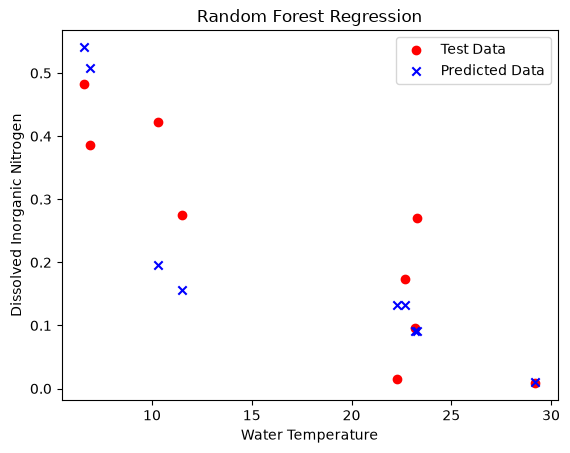

In [31]:
# These should already be defined, but define again in case this cell is being run before previous cells
temp = unstacked_data[['WTEMP']]
DIN = unstacked_data[['DIN']]
DIN = DIN.squeeze()

# Split the data into training vs. testing datasets
temp_train,temp_test,DIN_train,DIN_test = train_test_split(temp,DIN,test_size=0.2,random_state=4) 

# Choose the number of trees in the forest = 'k'
# k  = int(input('Choose a number for k: '))

# Initiate the RF regression model, setting its 'k' parameter (number of trees in the forest) to 'k' that we chose above.
RF_model = RandomForestRegressor(n_estimators=200,max_depth=None,)
RF_model.fit(temp_train, DIN_train)

# Predict DIN values with the model fit
DIN_pred = RF_model.predict(temp_test)

# Compute the R-squared score between the test DIN data and the predicted DIN data
print('Coefficient of determination (R-squared): %.2f'
      % r2_score(DIN_test, DIN_pred))

# Plot the model together with the data
plt.scatter(temp_test, DIN_test, color='red', label="Test Data")
plt.scatter(temp_test, DIN_pred, marker='x', color='blue', label="Predicted Data")
plt.xlabel('Water Temperature')
plt.ylabel('Dissolved Inorganic Nitrogen')
plt.legend()
plt.title('Random Forest Regression')
plt.show()

In [31]:
# Will need to look at the dataframe again
unstacked_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 30 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Station     42 non-null     str    
 1   SampleDate  42 non-null     str    
 2   SampleTime  42 non-null     str    
 3   CHLA        42 non-null     float64
 4   DIN         42 non-null     float64
 5   DO          42 non-null     float64
 6   DON         42 non-null     float64
 7   DOP         42 non-null     float64
 8   KD          42 non-null     float64
 9   NH4F        42 non-null     float64
 10  NO23F       42 non-null     float64
 11  NO2F        42 non-null     float64
 12  NO3F        42 non-null     float64
 13  PC          42 non-null     float64
 14  PH          42 non-null     float64
 15  PHEO        42 non-null     float64
 16  PN          42 non-null     float64
 17  PO4F        42 non-null     float64
 18  PP          42 non-null     float64
 19  SALINITY    42 non-null     float64
 20  S

Coefficient of determination (R-squared): 0.75


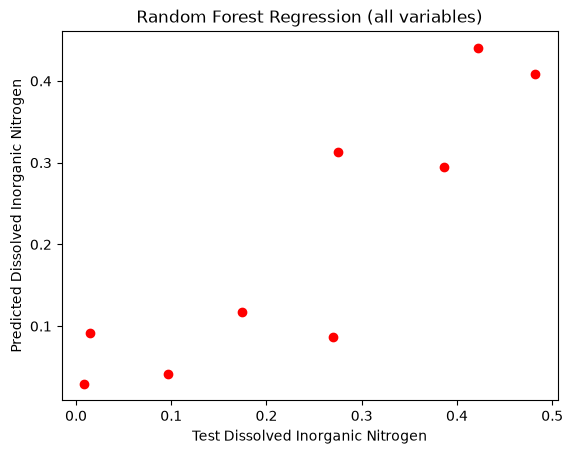

Feature 1 importance: 0.298
Feature 2 importance: 0.032
Feature 3 importance: 0.104
Feature 4 importance: 0.206
Feature 5 importance: 0.032
Feature 6 importance: 0.091
Feature 7 importance: 0.056
Feature 8 importance: 0.044
Feature 9 importance: 0.083
Feature 10 importance: 0.003
Feature 11 importance: 0.051


In [36]:
# After doing a little bit of reading about random forest models, I learned that they are useful for 
# identifying which columns in your dataset are best for building the model. So I wanted to explore that here
# because I think this could be very useful in my class project.

# Have to define the predictor variables, and then extract just the predictor and target variables

predictor_cols = [
    "WTEMP", # Feature 1
    "PH", # Feature 2
    "SALINITY", # Feature 3
    "DO", # Feature 4
    "SECCHI", # Feature 5
    "SPCOND", # Feature 6
    "SIGMA_T", # Feature 7
    "CHLA", # Feature 8
    "TSS", # Feature 9
    "PO4F", # Feature 10
    "TP", # Feature 11
]

x = unstacked_data[predictor_cols] # Define/extract predictor variables (intentionally not including any of the variables that already have N)
y = unstacked_data["DIN"] # Define/extract target variable

# Split the data into training data and testing data, like all of the other examples
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=4)

# Choose the number of trees in the forest = 'k'
# k  = int(input('Choose a number for k: '))

# Initiate the RF regression model, setting its 'k' parameter (number of trees in the forest) to 'k' that we chose above.
RF_model_II = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=None) 
RF_model_II.fit(x_train, y_train)

# Predict DIN values with the model fit
y_pred = RF_model_II.predict(x_test)

# Compute the R-squared score between the test DIN data and the predicted DIN data
print('Coefficient of determination (R-squared): %.2f'
      % r2_score(y_test, y_pred))

# This is a little different from the other plots I've made in this script
# Plot the modeled data against the real data
plt.scatter(y_test, y_pred, color='red')
#plt.scatter(x_test, y_pred, marker='x', color='blue', label="Predicted Data")
plt.ylabel('Predicted Dissolved Inorganic Nitrogen')
plt.xlabel('Test Dissolved Inorganic Nitrogen')
#plt.legend()
plt.title('Random Forest Regression (all variables)')
plt.show()

# Also look at the feature importance - the order of the features corresponds to the order of the predictor columns
feature_importances = RF_model_II.feature_importances_
for idx, importance in enumerate(feature_importances):
    print(f"Feature {idx+1} importance: {importance:.3f}")

Hyperparameter tuning:

For the simple linear regressions, really the only thing that changes is the dependent variable, or the variable you're using to predict the target variable. This is why I made three separate linear regressions, and I picked predictor variables that were more physical than biological honestly because that's just what I'm more familiar with in my own research. Out of water temperature, salinity, and pH, water temperature was the best predictor of DIN.

For the K nearest-neighbors regression, I chose the number of nearest neighbors by playing around with different options until I optimized the R2 value, which turned out to be 5. I think this makes sense for a relatively small dataset. Another hyper-parameter I adjusted was the weighting of the nearest neighbors. The options are "uniform," which treats all nearest neighbors equally, or "distance," which means the closer neighbors have more of an effect on the regression. "Uniform" gave higher R2s for this model, which I think is also related to it being a relatively small dataset.

For the random forest regression, the main hyperparameter to adjust is the number of estimators, which means the number of trees (decision trees) in the "forest" the model constructs. After playing around with this, what I found was that giving the model a lot of opportunities (>100) to come to a decision improved the R2, but giving it too many (>200) decreased its performance. I also set the tree depth to none, which means each tree basically gets unlimited tries to come to a decision. There were many more hyperparameters that could be tuned, but according to the documentation of this package on SkiKitLearn, these two were the most important/basic.

The random forest model improved a lot when it could draw from the entire dataset of available predictor variables. The top three most important predictor variables for DIN were: water temperature, dissolved oxygen, and salinity. 